In [97]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
housing_data = fetch_california_housing(as_frame=True)
housing_df = housing_data.frame
print("Shape:", housing_df.shape)
print("Columns:\n", housing_df.columns)
display(housing_df.info())

Shape: (20640, 9)
Columns:
 Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


None

In [98]:
print("Missing values per column:\n", housing_df.isna().sum())

Missing values per column:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [99]:
display(housing_df.describe())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [100]:
display(housing_df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


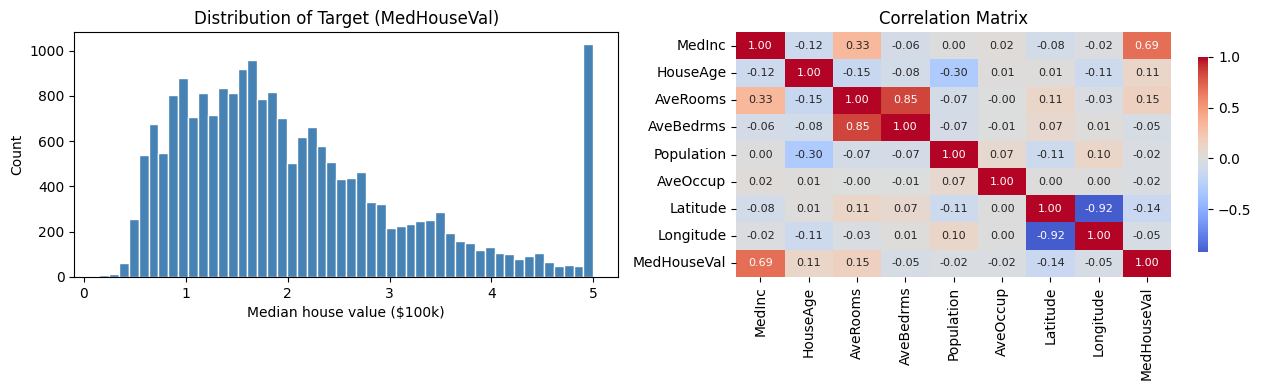

In [101]:
# Distribution of the target and correlations
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(housing_df["MedHouseVal"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Target (MedHouseVal)")
axes[0].set_xlabel("Median house value ($100k)")
axes[0].set_ylabel("Count")

corr = housing_df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1],
            cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
axes[1].set_title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [102]:

X = housing_df.drop("MedHouseVal", axis=1)

#target variable
y = housing_df["MedHouseVal"]
print("X shape:")
display(X.shape)

print("y shape:")
y.shape

X shape:


(20640, 8)

y shape:


(20640,)

In [103]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (16512, 8)  Test: (4128, 8)


In [104]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [105]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Lasso (alpha=0.001)": Lasso(alpha=0.001, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

def evaluate(model, X_tr, y_tr, X_te, y_te):
    """Fit a model and return train/test metrics: MAE, MSE, RMSE, R²."""
    model.fit(X_tr, y_tr)
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)

    def metrics(y_true, y_pred):
        mae = mean_absolute_error(y_true, y_pred)
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_true, y_pred)
        return mae, mse, rmse, r2

    return metrics(y_tr, pred_tr), metrics(y_te, pred_te), pred_te

results = []
test_predictions = {}

for name, model in models.items():
    (tr_mae, tr_mse, tr_rmse, tr_r2), (te_mae, te_mse, te_rmse, te_r2), pred_te = \
        evaluate(model, X_train_scaled, y_train, X_test_scaled, y_test)
    test_predictions[name] = pred_te
    results.append({
        "Model": name,
        "MAE (test)": te_mae, "MSE (test)": te_mse,
        "RMSE (test)": te_rmse, "R² (test)": te_r2,
        "RMSE (train)": tr_rmse, "R² (train)": tr_r2,
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.sort_values("RMSE (test)").round(4)

,MAE (test),MSE (test),RMSE (test),R² (test),RMSE (train),R² (train)
Model,,,,,,
Random Forest,0.3268,0.2542,0.5042,0.8060,0.1858,0.9742
Gradient Boosting,0.3717,0.2940,0.5422,0.7756,0.5107,0.8049
Decision Tree,0.4532,0.4930,0.7021,0.6238,0.0000,1.0000
Lasso (alpha=0.001),0.5331,0.5545,0.7446,0.5769,0.7197,0.6125
Ridge (alpha=1.0),0.5332,0.5559,0.7456,0.5758,0.7197,0.6126
Linear Regression,0.5332,0.5559,0.7456,0.5758,0.7197,0.6126


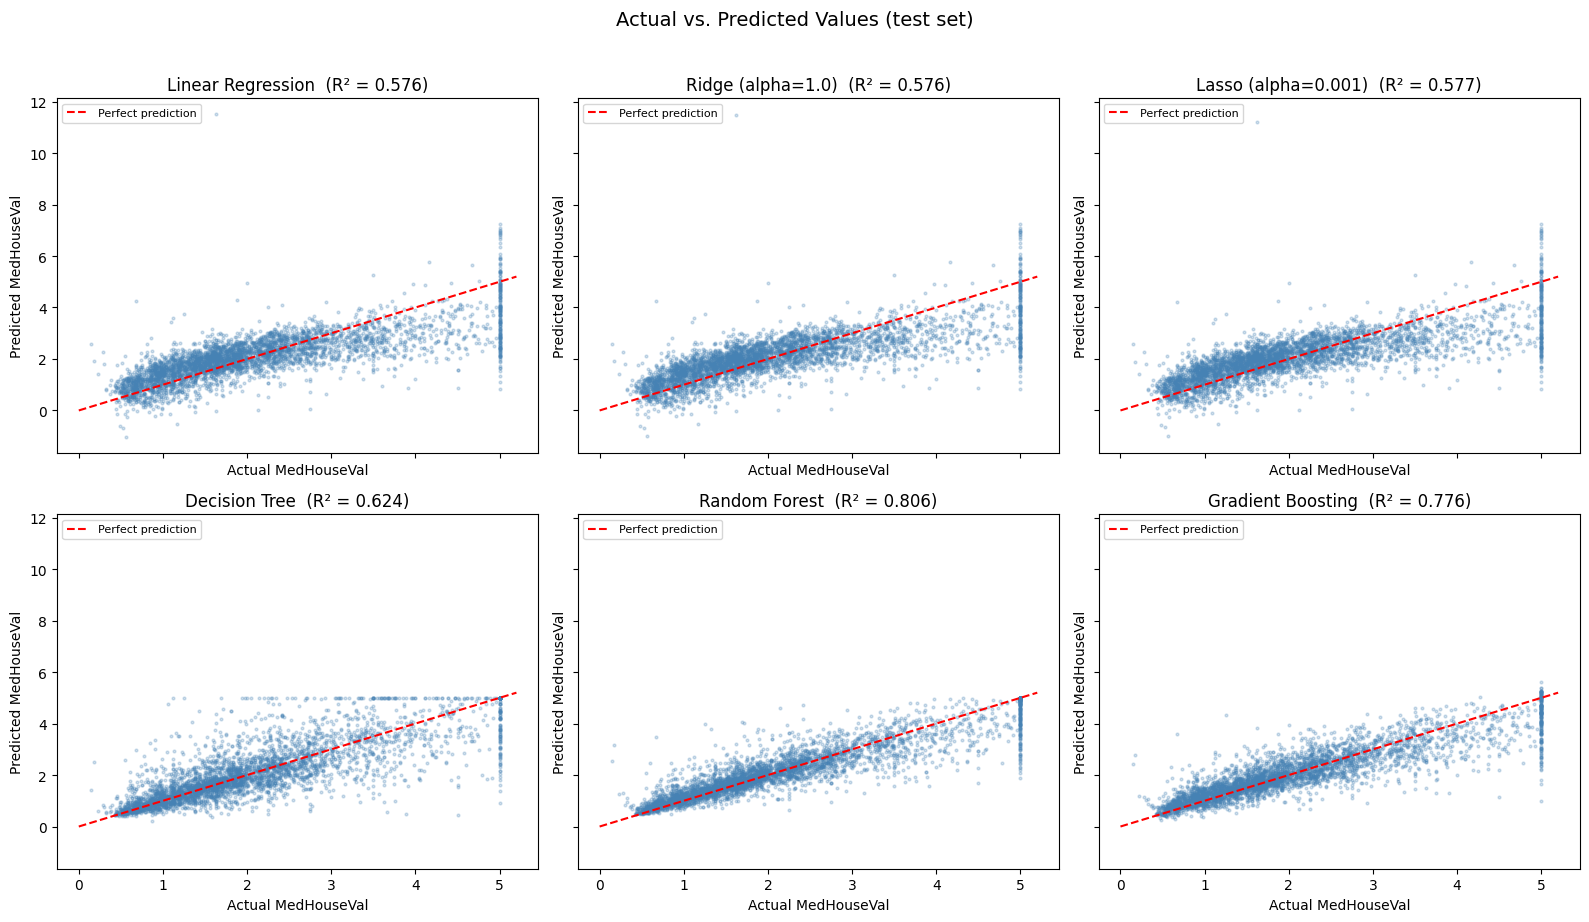

In [106]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)

for ax, (name, pred) in zip(axes.ravel(), test_predictions.items()):
    ax.scatter(y_test, pred, s=4, alpha=0.25, color="steelblue")
    lims = [0, 5.2]
    ax.plot(lims, lims, "r--", linewidth=1.5, label="Perfect prediction")
    r2 = r2_score(y_test, pred)
    ax.set_title(f"{name}  (R² = {r2:.3f})")
    ax.set_xlabel("Actual MedHouseVal")
    ax.set_ylabel("Predicted MedHouseVal")
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle("Actual vs. Predicted Values (test set)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

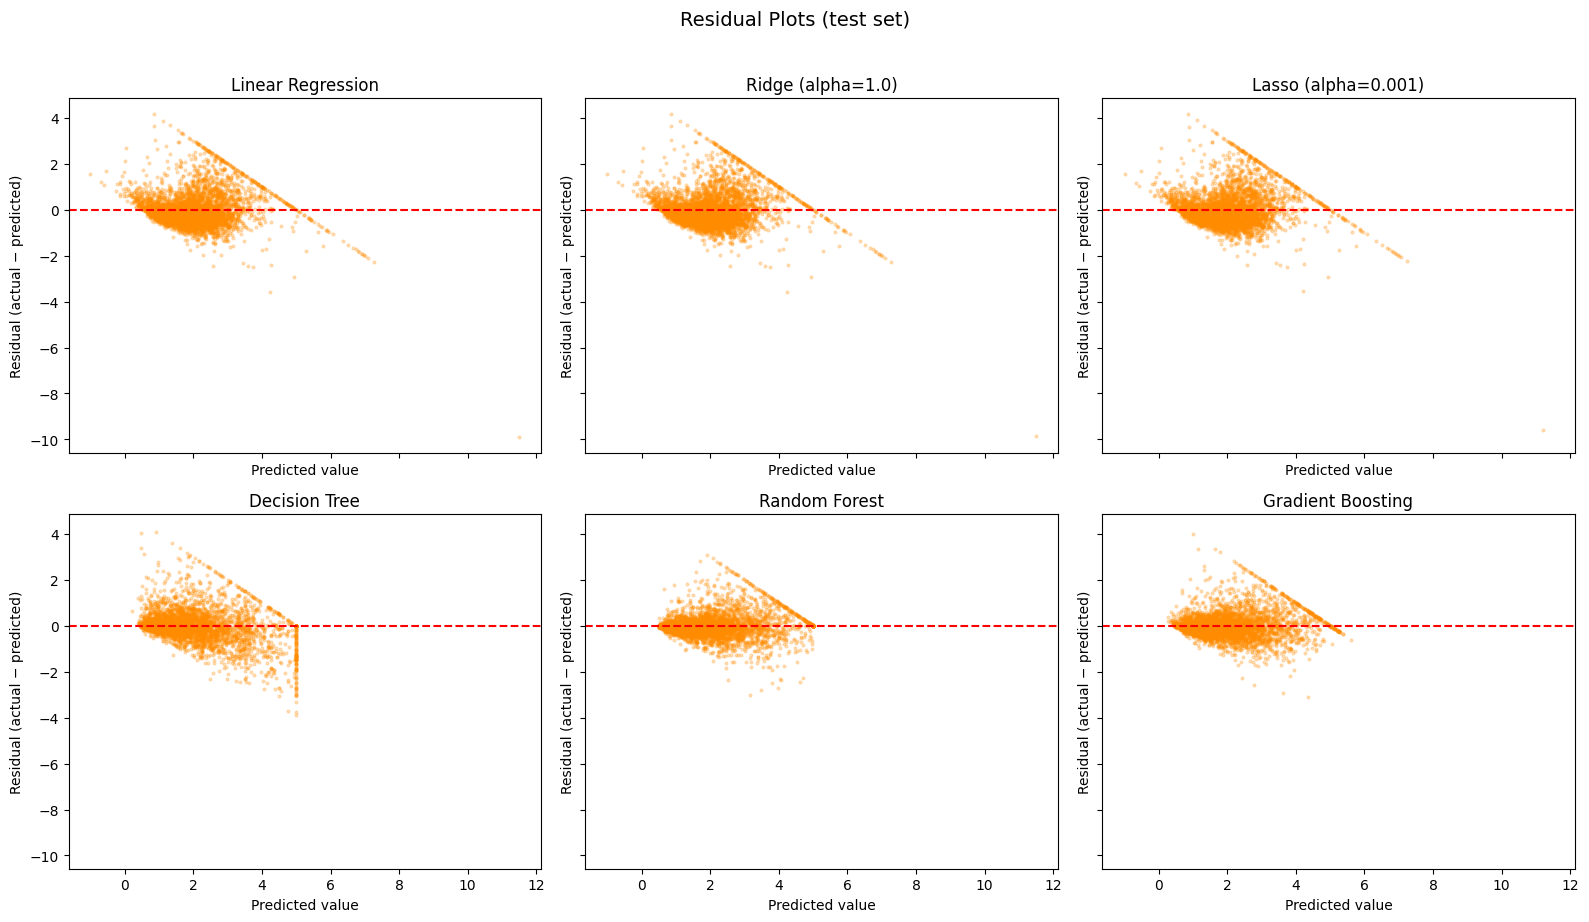

In [107]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)

for ax, (name, pred) in zip(axes.ravel(), test_predictions.items()):
    residuals = y_test - pred
    ax.scatter(pred, residuals, s=4, alpha=0.25, color="darkorange")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(name)
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual (actual − predicted)")

plt.suptitle("Residual Plots (test set)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

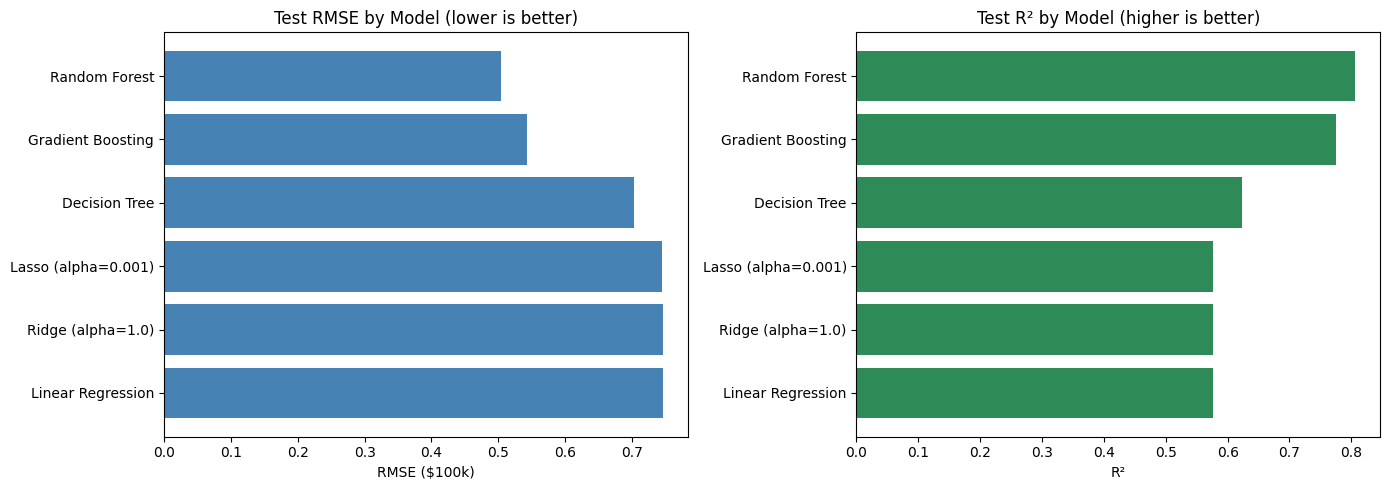

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = results_df.sort_values("RMSE (test)").index

axes[0].barh(order, results_df.loc[order, "RMSE (test)"], color="steelblue")
axes[0].set_title("Test RMSE by Model (lower is better)")
axes[0].set_xlabel("RMSE ($100k)")
axes[0].invert_yaxis()

axes[1].barh(order, results_df.loc[order, "R² (test)"], color="seagreen")
axes[1].set_title("Test R² by Model (higher is better)")
axes[1].set_xlabel("R²")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

Random Forest is chosen as the best performing model, on the dataset, scoring the lowest RMSE of 0.50, and R2 of 0.80. To further explain, this accounts for 80% of the variance in house values, with an error of about $50.000